# Inicializacion constantes


In [19]:
# Importación de librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
import time

# --- CONSTANTES FÍSICAS ---
# Constante de Boltzmann (J/K)
k_B = 1.380649e-23 
# Temperatura ambiente en Kelvin (aprox 27 °C)
T = 300.0           
# Energía mínima para destruir 1 bit (Joules)
E_bit = k_B * T * np.log(2) 
# Asumimos que un entero en Python ocupa 64 bits
W_BITS = 64         

print(f"Energía de borrar 1 bit a {T}K: {E_bit:.4e} Joules")

Energía de borrar 1 bit a 300.0K: 2.8710e-21 Joules


# Algoritmo O(n^2)

In [20]:
def insertion_sort_energy(arr):
    """Ordena con Insertion Sort y contabiliza las escrituras del arreglo.

    Args:
        arr: Arreglo con los valores que se desean ordenar.

    Returns:
        int: Bits estimados según la regla de escrituras del notebook.
    """
    arr = arr.copy()  # Copia para no modificar el arreglo original
    bits_destroyed = 0

    for i in range(1, len(arr)):
        key = arr[i]
        j = i - 1
        while j >= 0 and arr[j] > key:
            arr[j + 1] = arr[j]  # Sobrescritura -> Destruye 64 bits
            bits_destroyed += W_BITS
            j -= 1
        arr[j + 1] = key  # Inserción final -> Destruye 64 bits
        bits_destroyed += W_BITS

    return bits_destroyed


# Prueba rápida con un arreglo pequeño
test_arr = [5, 2, 4, 6, 1, 3]
bits_test_ins = insertion_sort_energy(test_arr)
print(f"Insertion Sort destruyó {bits_test_ins} bits en el arreglo de prueba.")


Insertion Sort destruyó 896 bits en el arreglo de prueba.


# Algoritmo O(n log n)

In [21]:
def merge_sort_energy(arr):
    """Ordena con Merge Sort y contabiliza escrituras en arreglos auxiliares.

    Args:
        arr: Arreglo con los valores que se desean ordenar.

    Returns:
        int: Bits estimados según la regla de escrituras del notebook.
    """
    arr = arr.copy()
    bits_destroyed = [0]  # Lista para poder modificar el valor por referencia

    def merge(left, right):
        """Fusiona dos subarreglos ordenados y actualiza el contador.

        Args:
            left: Primera mitad ordenada.
            right: Segunda mitad ordenada.

        Returns:
            list: Arreglo con ambas mitades fusionadas y ordenadas.
        """
        result = []
        i = j = 0
        # Fusión de los dos sub-arreglos
        while i < len(left) and j < len(right):
            if left[i] < right[j]:
                result.append(left[i])
                i += 1
            else:
                result.append(right[j])
                j += 1
            bits_destroyed[0] += W_BITS  # Escritura en memoria auxiliar

        # Agregar los elementos restantes
        result.extend(left[i:])
        result.extend(right[j:])
        bits_destroyed[0] += (
            len(left[i:]) + len(right[j:])
        ) * W_BITS
        return result

    def sort(sub_arr):
        """Divide recursivamente el arreglo y ordena cada mitad.

        Args:
            sub_arr: Subarreglo que se quiere ordenar.

        Returns:
            list: Subarreglo ordenado.
        """
        if len(sub_arr) <= 1:
            return sub_arr
        mid = len(sub_arr) // 2
        left = sort(sub_arr[:mid])
        right = sort(sub_arr[mid:])
        return merge(left, right)

    sort(arr)
    return bits_destroyed[0]


# Prueba rápida
bits_test_mer = merge_sort_energy(test_arr)
print(f"Merge Sort destruyó {bits_test_mer} bits en el arreglo de prueba.")


Merge Sort destruyó 1024 bits en el arreglo de prueba.


In [22]:
def heapsort_energy(arr, verificar=False):
    """Ordena con Heapsort y contabiliza las escrituras por intercambios.

    Args:
        arr: Arreglo con los valores que se desean ordenar.
        verificar: Indica si se comprueba el ordenamiento.

    Returns:
        int: Bits estimados según la regla de escrituras del notebook.
    """
    arr = arr.copy()
    bits_destroyed = 0
    n = len(arr)

    def heapify(tamano, raiz):
        """Restablece la propiedad de montículo desde la raíz indicada.

        Args:
            tamano: Cantidad de elementos que forman el montículo.
            raiz: Posición desde la que se revisa el montículo.
        """
        nonlocal bits_destroyed

        while True:
            mayor = raiz
            izquierdo = 2 * raiz + 1
            derecho = 2 * raiz + 2

            if izquierdo < tamano and arr[izquierdo] > arr[mayor]:
                mayor = izquierdo

            if derecho < tamano and arr[derecho] > arr[mayor]:
                mayor = derecho

            if mayor == raiz:
                break

            arr[raiz], arr[mayor] = arr[mayor], arr[raiz]
            bits_destroyed += 2 * W_BITS
            raiz = mayor

    for i in range(n // 2 - 1, -1, -1):
        heapify(n, i)

    for fin in range(n - 1, 0, -1):
        arr[0], arr[fin] = arr[fin], arr[0]
        bits_destroyed += 2 * W_BITS
        heapify(fin, 0)

    if verificar:
        assert list(arr) == sorted(arr)

    return bits_destroyed

print("Heapsort:", heapsort_energy(test_arr, verificar=True), "bits")



Heapsort: 1408 bits


In [23]:
def quicksort_energy(arr, verificar=False):
    """Ordena con Quicksort y contabiliza escrituras por intercambios.

    Args:
        arr: Arreglo con los valores que se desean ordenar.
        verificar: Indica si se comprueba el ordenamiento.

    Returns:
        int: Bits estimados según la regla de escrituras del notebook.
    """
    arr = arr.copy()
    bits_destroyed = 0
    pendientes = [(0, len(arr) - 1)]

    while pendientes:
        inicio, fin = pendientes.pop()

        if inicio >= fin:
            continue

        medio = (inicio + fin) // 2

        if medio != fin:
            arr[medio], arr[fin] = arr[fin], arr[medio]
            bits_destroyed += 2 * W_BITS

        pivote = arr[fin]
        i = inicio - 1

        for j in range(inicio, fin):
            if arr[j] <= pivote:
                i += 1

                if i != j:
                    arr[i], arr[j] = arr[j], arr[i]
                    bits_destroyed += 2 * W_BITS

        posicion = i + 1

        if posicion != fin:
            arr[posicion], arr[fin] = arr[fin], arr[posicion]
            bits_destroyed += 2 * W_BITS

        pendientes.append((inicio, posicion - 1))
        pendientes.append((posicion + 1, fin))

    if verificar:
        assert list(arr) == sorted(arr)

    return bits_destroyed


print("Quicksort:", quicksort_energy(test_arr, verificar=True), "bits")

Quicksort: 1152 bits


# Simulacion

In [24]:
# Definimos los tamaños de arreglo a probar (puedes aumentarlos si tu PC es rápida)
n_values = [10, 50, 100, 200, 500, 1000, 2000, 3000]

# Resultados de energía
energy_insertion = []
energy_merge = []
energy_heap = []
energy_quick = []

# Resultados de tiempo
time_insertion = []
time_merge = []
time_heap = []
time_quick = []


print("Iniciando simulación...")
for n in n_values:
    arr = np.random.randint(0, 10000, n) # Datos aleatorios
    
    # Medir Insertion Sort
    inicio = time.time()
    bits_ins = insertion_sort_energy(arr)
    time_insertion.append(time.time() - inicio)
    energy_insertion.append(bits_ins * E_bit)
    
    # Medir Merge Sort
    inicio = time.time()
    bits_mer = merge_sort_energy(arr)
    time_merge.append(time.time() - inicio)
    energy_merge.append(bits_mer * E_bit)
    
    # medir Heapsort
    inicio = time.time()
    bits_heap = heapsort_energy(arr)
    time_heap.append(time.time() - inicio)
    energy_heap.append(bits_heap * E_bit)

    # medir Quicksort
    inicio = time.time()
    bits_quick = quicksort_energy(arr)
    time_quick.append(time.time() - inicio)
    energy_quick.append(bits_quick * E_bit)
    
    print(f"n={n} completado.")
    
print("Simulación terminada.")

Iniciando simulación...
n=10 completado.
n=50 completado.
n=100 completado.
n=200 completado.
n=500 completado.
n=1000 completado.
n=2000 completado.
n=3000 completado.
Simulación terminada.


# Resultados: Energía vs Tamaño de entrada

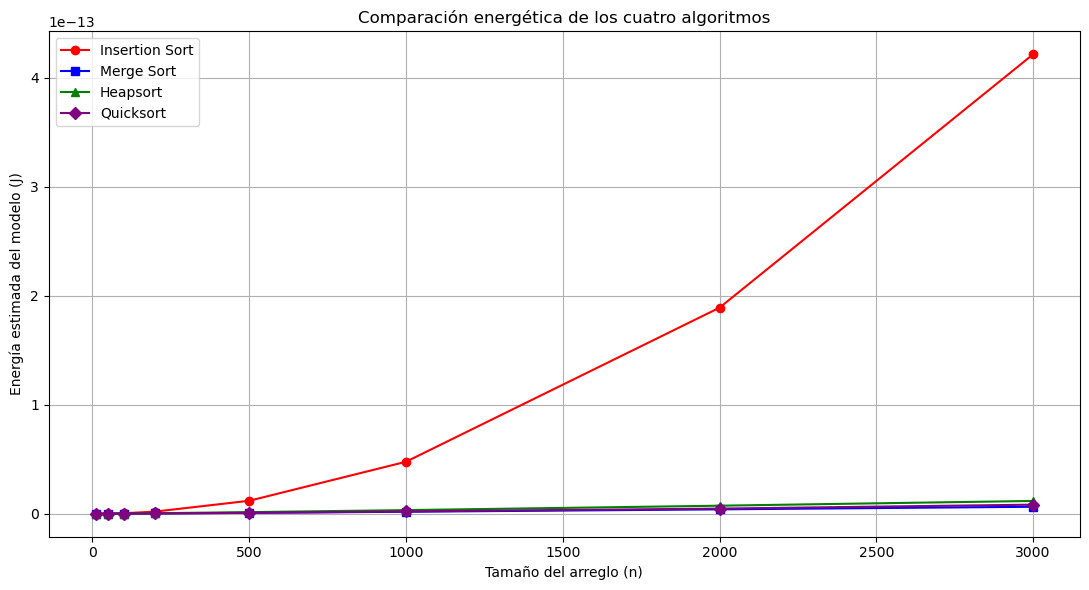

In [25]:

plt.figure(figsize=(11, 6))

plt.plot(n_values, energy_insertion,
         marker='o', color='red', label='Insertion Sort')

plt.plot(n_values, energy_merge,
         marker='s', color='blue', label='Merge Sort')

plt.plot(n_values, energy_heap,
         marker='^', color='green', label='Heapsort')

plt.plot(n_values, energy_quick,
         marker='D', color='purple', label='Quicksort')

plt.title('Comparación energética de los cuatro algoritmos')
plt.xlabel('Tamaño del arreglo (n)')
plt.ylabel('Energía estimada del modelo (J)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Validación: Gráfica Log-Log

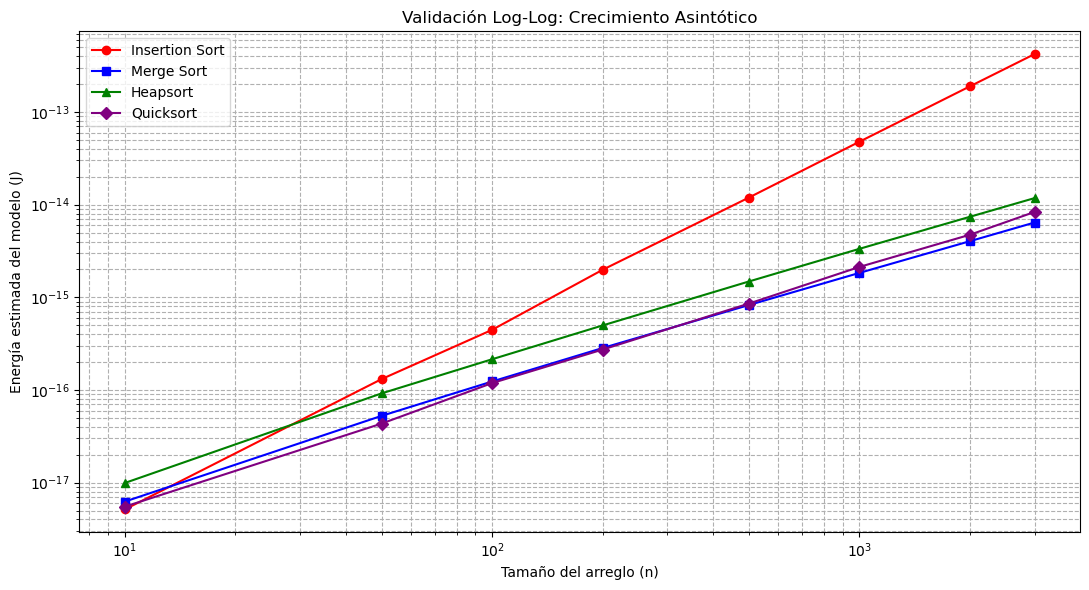

Insertion Sort: 1.98
Merge Sort: 1.20
Heapsort: 1.23
Quicksort: 1.28


In [26]:

plt.figure(figsize=(11, 6))

plt.loglog(n_values, energy_insertion,
           marker='o', color='red', label='Insertion Sort')

plt.loglog(n_values, energy_merge,
           marker='s', color='blue', label='Merge Sort')

plt.loglog(n_values, energy_heap,
           marker='^', color='green', label='Heapsort')

plt.loglog(n_values, energy_quick,
           marker='D', color='purple', label='Quicksort')

# Pendientes aproximadas
pendiente_ins = np.polyfit(
    np.log(n_values), np.log(energy_insertion), 1
)[0]

pendiente_mer = np.polyfit(
    np.log(n_values), np.log(energy_merge), 1
)[0]

pendiente_heap = np.polyfit(
    np.log(n_values), np.log(energy_heap), 1
)[0]

pendiente_quick = np.polyfit(
    np.log(n_values), np.log(energy_quick), 1
)[0]

plt.title('Validación Log-Log: Crecimiento Asintótico')
plt.xlabel('Tamaño del arreglo (n)')
plt.ylabel('Energía estimada del modelo (J)')
plt.legend()
plt.grid(True, which='both', linestyle='--')
plt.tight_layout()
plt.show()

print(f"Insertion Sort: {pendiente_ins:.2f}")
print(f"Merge Sort: {pendiente_mer:.2f}")
print(f"Heapsort: {pendiente_heap:.2f}")
print(f"Quicksort: {pendiente_quick:.2f}")


# Extra: Validación de Tiempos Reales

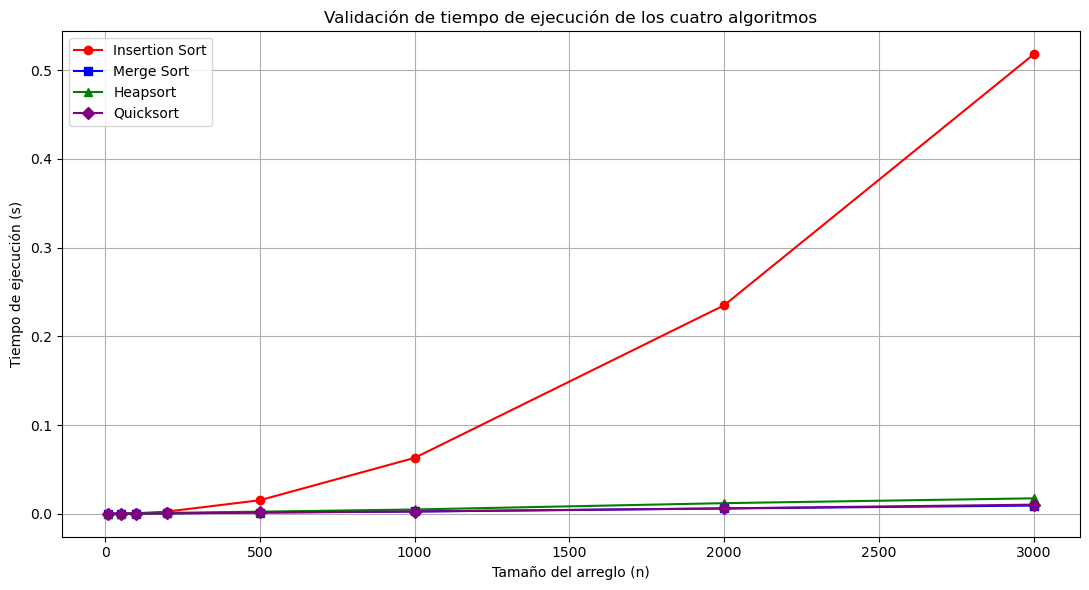

In [27]:

plt.figure(figsize=(11, 6))

plt.plot(n_values, time_insertion,
         marker='o', color='red', label='Insertion Sort')

plt.plot(n_values, time_merge,
         marker='s', color='blue', label='Merge Sort')

plt.plot(n_values, time_heap,
         marker='^', color='green', label='Heapsort')

plt.plot(n_values, time_quick,
         marker='D', color='purple', label='Quicksort')

plt.title('Validación de tiempo de ejecución de los cuatro algoritmos')
plt.xlabel('Tamaño del arreglo (n)')
plt.ylabel('Tiempo de ejecución (s)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
